<a href="https://colab.research.google.com/github/0110225176-png/Machine-Learning/blob/main/Tugas_Praktikum05_Labibah_0110225176_Elyas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Membaca file csv menggunakan pandas
df = pd.read_csv('/content/drive/MyDrive/Semester03/ML 2026/Praktikum05/data/dataset_iris.csv')
df.head()

# Menampilkan informasi detail
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [4]:
print("\n--- Cek Missing Value ---")
print(df.isnull().sum())



--- Cek Missing Value ---
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [ ]:
print("Jumlah duplikat:", df.duplicated().sum())

Jumlah duplikat: 0


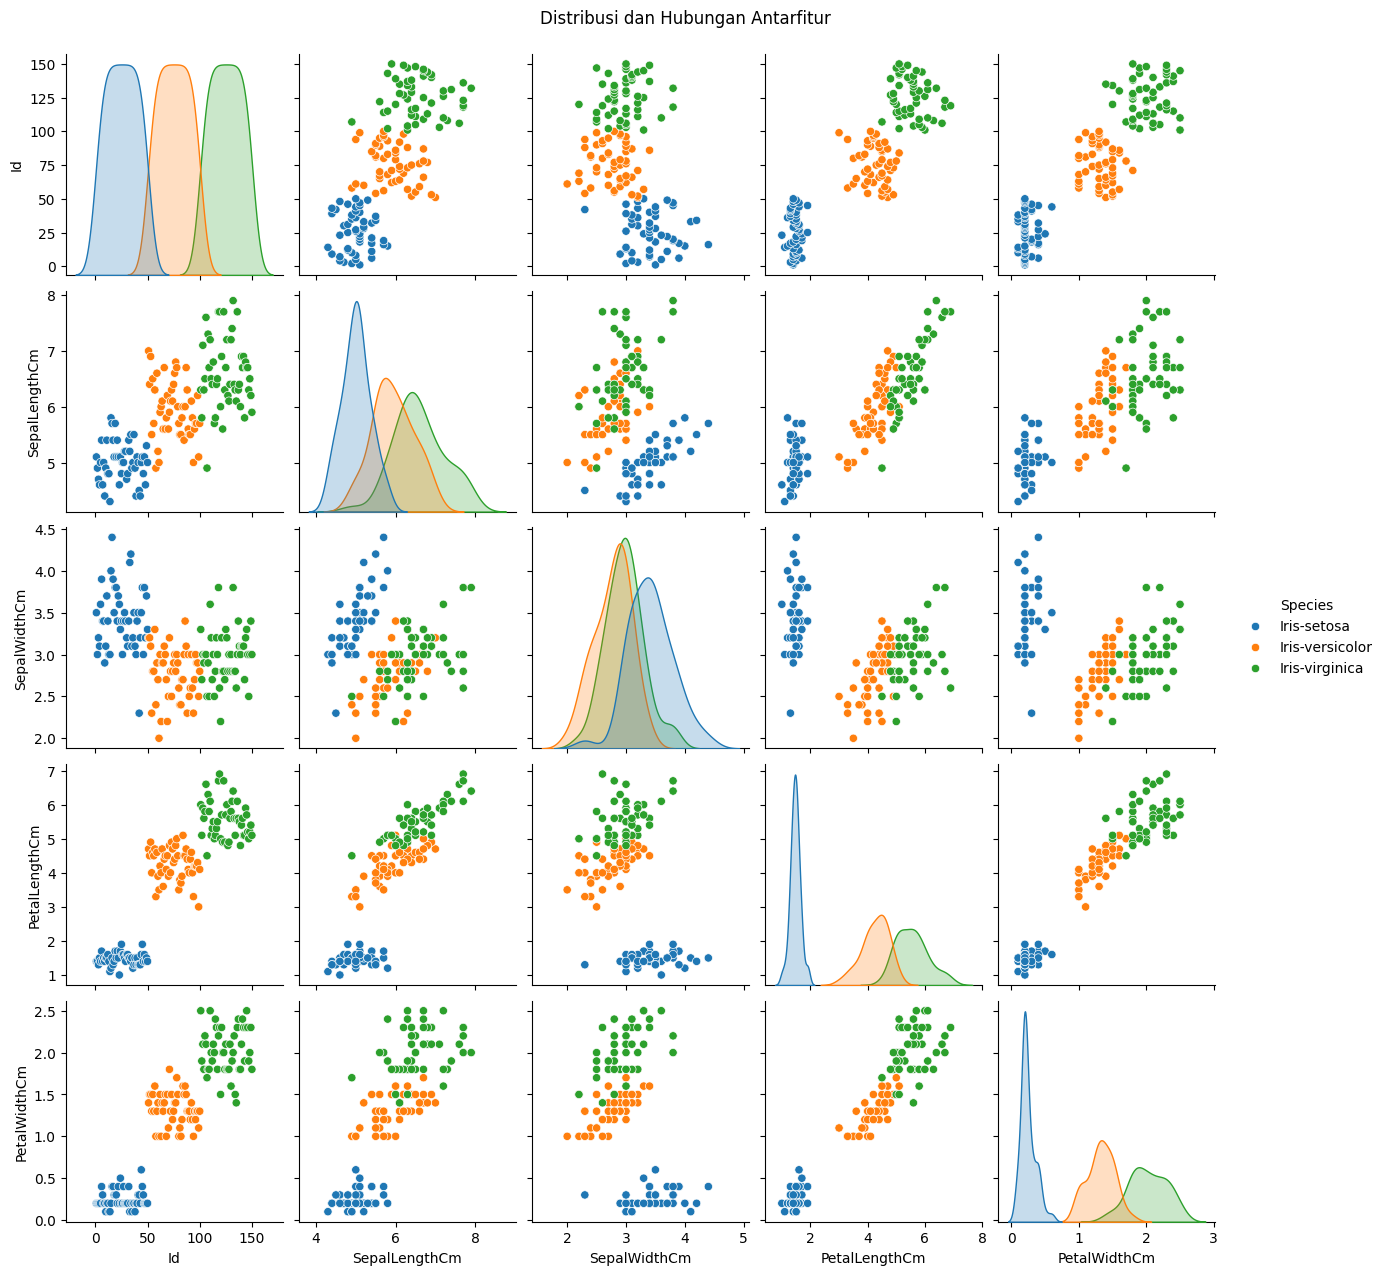

In [5]:
# Eksplorasi & Visualisasi Distribusi
sns.pairplot(df, hue='Species')
plt.suptitle("Distribusi dan Hubungan Antarfitur", y=1.02)
plt.show()

In [6]:
# Menentukan Fitur (X) dan Target (y)

# Kolom 'Id' dibuang karena hanya berupa nomor urut, bukan fitur pengukuran
X = df.drop(columns=['Id', 'Species'])
y = df['Species']

In [7]:
# Membagi Dataset (80% Train, 20% Test)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [8]:
X = df.drop(columns=['Id', 'Species'])
y = df['Species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [9]:
# membangun dan melatih model desicion tree

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [11]:
#evalulasi performa model
y_pred = model.predict(X_test)

print("\n--- Hasil Evaluasi Model ---")
print("akurasi model:", accuracy_score(y_test, y_pred))
print("\nLaporan Klasifikasi:\n", classification_report(y_test, y_pred))


--- Hasil Evaluasi Model ---
akurasi model: 0.9333333333333333

Laporan Klasifikasi:
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



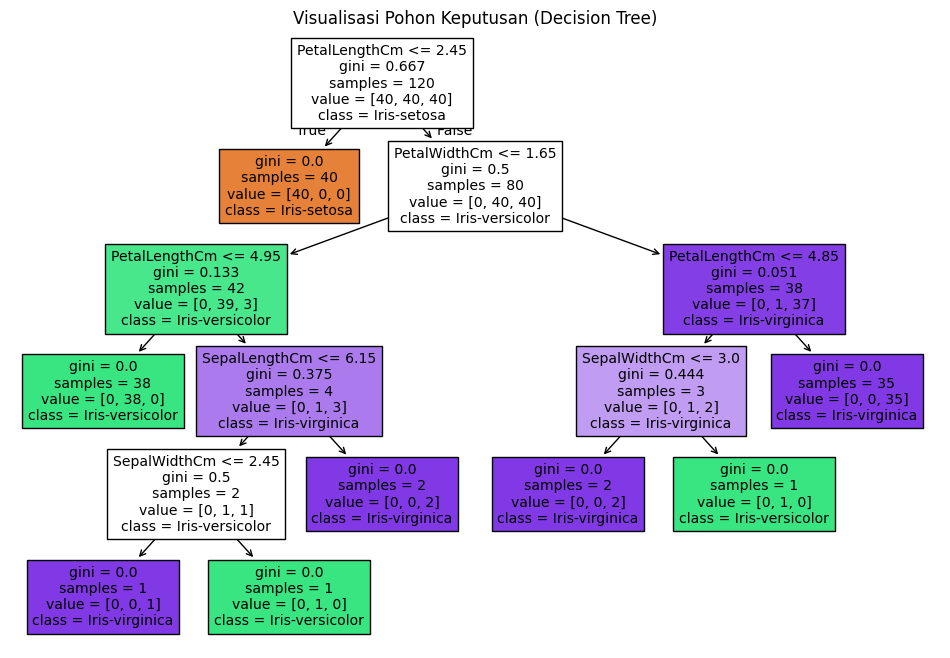

In [10]:
#visualisasi pohon keputusan

plt.figure(figsize=(12, 8))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True
)
plt.title("Visualisasi Pohon Keputusan (Decision Tree)")
plt.show()

In [12]:
data_baru = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2],
     [6.0, 2.8, 4.5, 1.4],
     [6.7, 3.1, 5.6, 2.4],
     [5.9, 3.0, 5.1, 1.8]],
    columns=X.columns)
data_baru["Prediksi"] = model.predict(data_baru)
print(data_baru)


   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm         Prediksi
0            5.1           3.5            1.4           0.2      Iris-setosa
1            6.0           2.8            4.5           1.4  Iris-versicolor
2            6.7           3.1            5.6           2.4   Iris-virginica
3            5.9           3.0            5.1           1.8   Iris-virginica


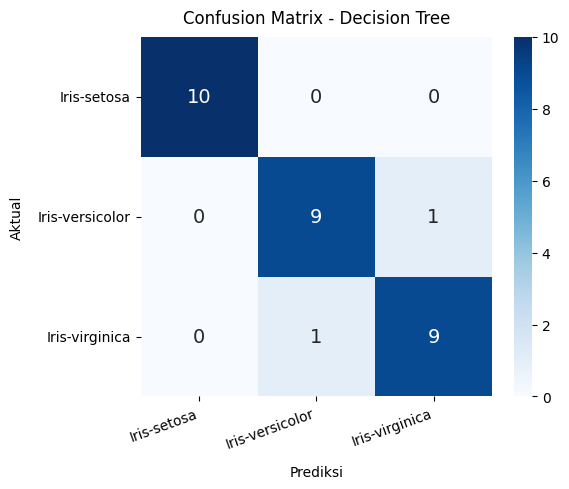

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Hitung Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# 2. Tentukan nama label kelas
labels = ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']

# 3. Buat plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    annot_kws={"size": 14}
)

# 4. Tambahkan Judul dan Label Sumbu
plt.title('Confusion Matrix - Decision Tree', pad=10)
plt.xlabel('Prediksi', labelpad=10)
plt.ylabel('Aktual', labelpad=10)

# Rotasi label pada sumbu X agar agak miring
plt.xticks(rotation=20, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()